### Credit Card Fraud Detection — Model Training
#### Objective: Train a baseline machine learning model to identify fraudulent transactions in a highly imbalanced dataset.

In [2]:
import pandas as pd
import numpy as np

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,
    roc_auc_score
)

X_train = pd.read_csv("../data/processed/X_train.csv")
X_test = pd.read_csv("../data/processed/X_test.csv")

y_train = pd.read_csv("../data/processed/y_train.csv").squeeze("columns")
y_test = pd.read_csv("../data/processed/y_test.csv").squeeze("columns")

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training fraud cases:", int(y_train.sum()))
print("Testing fraud cases:", int(y_test.sum()))

Training features: (226980, 30)
Testing features: (56746, 30)
Training fraud cases: 378
Testing fraud cases: 95


In [3]:
model_lr = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

model_lr.fit(X_train, y_train)


,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to u

In [4]:
# Predict transaction classes
y_pred = model_lr.predict(X_test)

# Predict fraud probabilities
y_proba = model_lr.predict_proba(X_test)[:, 1]

print("Predictions completed!")
print("Total predictions:", len(y_pred))
print("Predicted fraud cases:", int(y_pred.sum()))

Predictions completed!
Total predictions: 56746
Predicted fraud cases: 1476


In [5]:
print("Classification Report:\n")
print(classification_report(y_test, y_pred, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("Average Precision (PR-AUC summary):",
      average_precision_score(y_test, y_proba))

print("ROC-AUC:",
      roc_auc_score(y_test, y_proba))

Classification Report:

              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56651
           1       0.06      0.87      0.11        95

    accuracy                           0.98     56746
   macro avg       0.53      0.92      0.55     56746
weighted avg       1.00      0.98      0.99     56746

Confusion Matrix:
[[55258  1393]
 [   12    83]]
Average Precision (PR-AUC summary): 0.6719353631354262
ROC-AUC: 0.9658392242808925


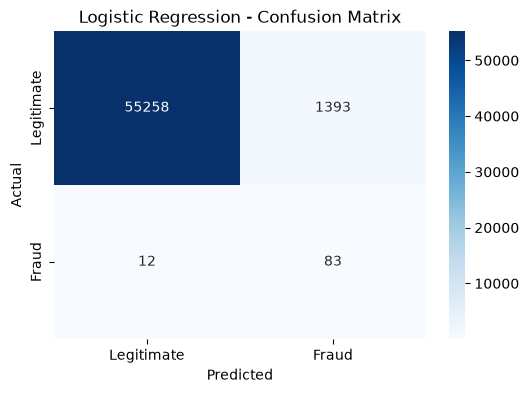

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Fraud"],
    yticklabels=["Legitimate", "Fraud"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [7]:
from sklearn.ensemble import RandomForestClassifier

model_rf = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

model_rf.fit(X_train, y_train)


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_fe

In [8]:
# Predictions
y_pred_rf = model_rf.predict(X_test)

# Fraud probabilities
y_proba_rf = model_rf.predict_proba(X_test)[:, 1]

print("Predicted fraud cases:", int(y_pred_rf.sum()))

Predicted fraud cases: 72


In [9]:
print("Random Forest Classification Report:\n")
print(classification_report(
    y_test,
    y_pred_rf,
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

print(
    "Average Precision (PR-AUC):",
    average_precision_score(y_test, y_proba_rf)
)

print(
    "ROC-AUC:",
    roc_auc_score(y_test, y_proba_rf)
)

Random Forest Classification Report:

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.96      0.73      0.83        95

    accuracy                           1.00     56746
   macro avg       0.98      0.86      0.91     56746
weighted avg       1.00      1.00      1.00     56746

Confusion Matrix:
[[56648     3]
 [   26    69]]
Average Precision (PR-AUC): 0.8033342967478889
ROC-AUC: 0.9474213768698282


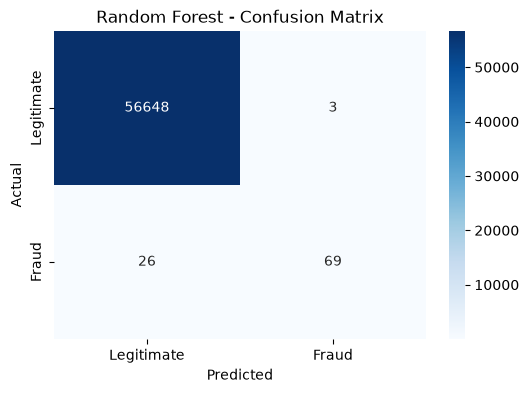

In [10]:
cm_rf = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Fraud"],
    yticklabels=["Legitimate", "Fraud"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest - Confusion Matrix")
plt.show()

##### Create Validation Set

In [11]:
from sklearn.model_selection import train_test_split

X_train_model, X_val, y_train_model, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Training data:", X_train_model.shape)
print("Validation data:", X_val.shape)
print("Test data:", X_test.shape)

print("\nTraining fraud cases:", int(y_train_model.sum()))
print("Validation fraud cases:", int(y_val.sum()))
print("Test fraud cases:", int(y_test.sum()))

Training data: (181584, 30)
Validation data: (45396, 30)
Test data: (56746, 30)

Training fraud cases: 302
Validation fraud cases: 76
Test fraud cases: 95


#### Random Forest — Validation Training

In [12]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)

# Train only on the training subset
model_rf_tuned = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

model_rf_tuned.fit(X_train_model, y_train_model)


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_fe

In [13]:
# Predict fraud probabilities on validation data
y_val_proba = model_rf_tuned.predict_proba(X_val)[:, 1]

print("Validation predictions generated!")
print("Number of validation transactions:", len(y_val_proba))
print("Actual validation fraud cases:", int(y_val.sum()))

print(
    "Validation Average Precision:",
    average_precision_score(y_val, y_val_proba)
)

Validation predictions generated!
Number of validation transactions: 45396
Actual validation fraud cases: 76
Validation Average Precision: 0.8714224243730699


In [14]:
import pandas as pd
import numpy as np

thresholds = [0.50, 0.40, 0.30, 0.20, 0.10, 0.05]

results = []

for threshold in thresholds:
    y_val_pred = (y_val_proba >= threshold).astype(int)

    results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, y_val_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, y_val_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_val, y_val_pred, zero_division=0
        ),
        "Fraud Flagged": int(y_val_pred.sum())
    })

threshold_results = pd.DataFrame(results)

threshold_results.round(4)

,Threshold,Precision,Recall,F1 Score,Fraud Flagged
0,0.50,0.9559,0.8553,0.9028,68
1,0.40,0.9559,0.8553,0.9028,68
2,0.30,0.9028,0.8553,0.8784,72
3,0.20,0.8442,0.8553,0.8497,77
4,0.10,0.6768,0.8816,0.7657,99
5,0.05,0.4323,0.8816,0.5801,155


In [15]:
# Combine training and validation data
X_train_final = pd.concat(
    [X_train_model, X_val],
    axis=0
).reset_index(drop=True)

y_train_final = pd.concat(
    [y_train_model, y_val],
    axis=0
).reset_index(drop=True)

print("Final training data:", X_train_final.shape)
print("Final training fraud cases:", int(y_train_final.sum()))

Final training data: (226980, 30)
Final training fraud cases: 378


In [16]:
final_model = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

final_model.fit(X_train_final, y_train_final)


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_fe

In [17]:
# Get fraud probabilities
y_test_proba_final = final_model.predict_proba(X_test)[:, 1]

# Apply selected threshold
best_threshold = 0.50

y_test_pred_final = (
    y_test_proba_final >= best_threshold
).astype(int)

print("Final predictions generated!")
print("Predicted fraud cases:", int(y_test_pred_final.sum()))

Final predictions generated!
Predicted fraud cases: 72


In [18]:
print("FINAL RANDOM FOREST RESULTS\n")

print("Classification Report:")
print(
    classification_report(
        y_test,
        y_test_pred_final,
        zero_division=0
    )
)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred_final))

print(
    "\nPR-AUC:",
    average_precision_score(
        y_test,
        y_test_proba_final
    )
)

print(
    "ROC-AUC:",
    roc_auc_score(
        y_test,
        y_test_proba_final
    )
)

FINAL RANDOM FOREST RESULTS

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.96      0.73      0.83        95

    accuracy                           1.00     56746
   macro avg       0.98      0.86      0.91     56746
weighted avg       1.00      1.00      1.00     56746

Confusion Matrix:
[[56648     3]
 [   26    69]]

PR-AUC: 0.8148634141015343
ROC-AUC: 0.9426053704631034


##### Random Forest Feature Importance
Feature importance shows which features contributed most to the
Random Forest's predictions.

The dataset contains PCA-transformed features V1-V28, along with
Time and Amount.

In [19]:
feature_importance = pd.DataFrame({
    "Feature": X_train_final.columns,
    "Importance": final_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance.head(10)

,Feature,Importance
14,V14,0.179779
10,V10,0.120677
12,V12,0.106021
4,V4,0.102388
17,V17,0.093397
3,V3,0.061969
16,V16,0.055932
11,V11,0.054240
2,V2,0.030317
7,V7,0.019631


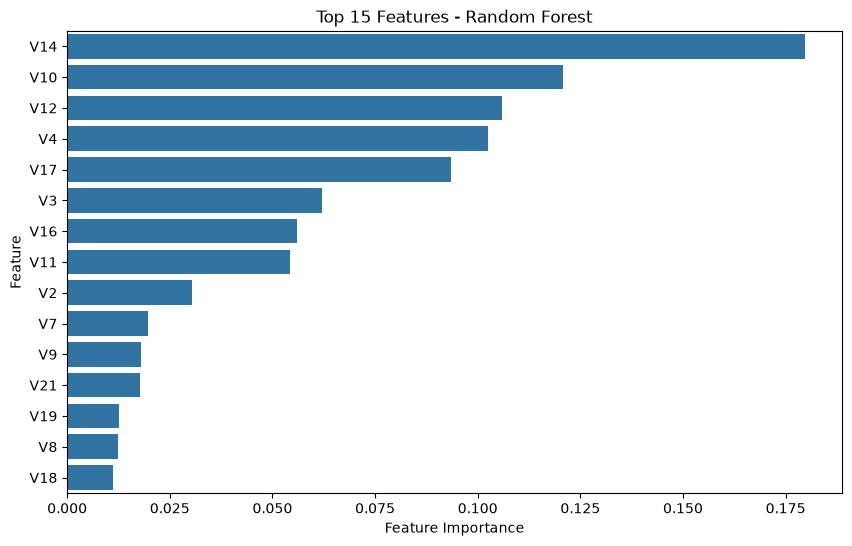

In [20]:
plt.figure(figsize=(10, 6))

top_features = feature_importance.head(15)

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Features - Random Forest")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.show()

In [21]:
feature_importance.to_csv(
    "../data/processed/feature_importance.csv",
    index=False
)

print("Feature importance saved successfully!")

Feature importance saved successfully!


In [23]:
import shap

print("SHAP version:", shap.__version__)

SHAP version: 0.52.0


#### SHAP Explainability
SHAP (SHapley Additive exPlanations) helps explain how individual
features contribute to a model prediction.

We will use TreeExplainer for the Random Forest model.

In [24]:
import shap

explainer = shap.TreeExplainer(final_model)

print("SHAP TreeExplainer created successfully!")

SHAP TreeExplainer created successfully!


In [25]:
# Select a small sample from the test set
X_shap = X_test.sample(
    n=500,
    random_state=42
)

print("SHAP sample shape:", X_shap.shape)

SHAP sample shape: (500, 30)


In [26]:
shap_values = explainer.shap_values(X_shap)

print("SHAP values calculated!")
print("Type:", type(shap_values))

SHAP values calculated!
Type: <class 'numpy.ndarray'>


In [27]:
print(type(shap_values))
print(np.array(shap_values).shape)

<class 'numpy.ndarray'>
(500, 30, 2)


In [28]:
shap_values_fraud = shap_values[:, :, 1]

print("Fraud SHAP shape:", shap_values_fraud.shape)

Fraud SHAP shape: (500, 30)


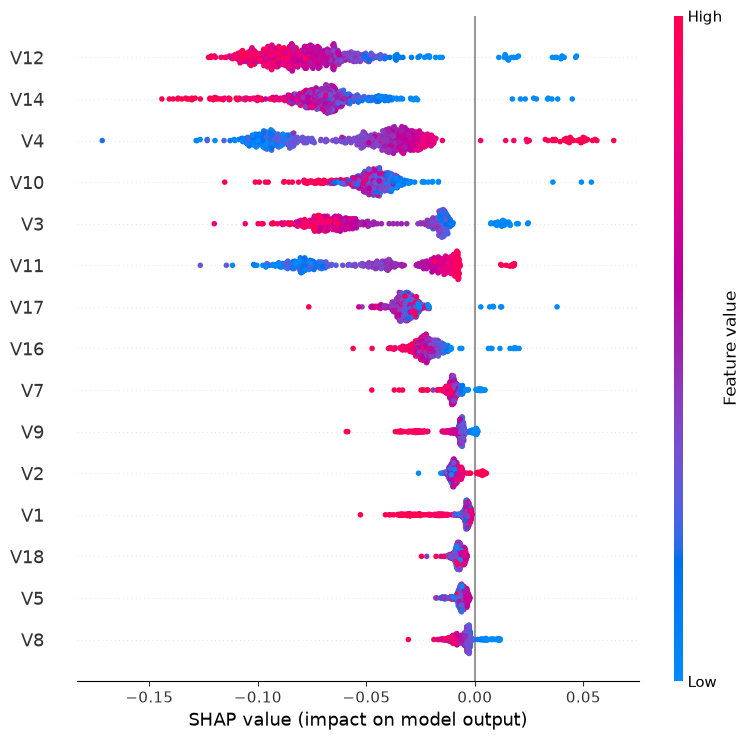

In [29]:
shap.summary_plot(
    shap_values_fraud,
    X_shap,
    max_display=15
)

In [30]:
# Select one transaction from our SHAP sample
transaction_index = 0

X_one = X_shap.iloc[[transaction_index]]

print(X_one)

          Time        V1        V2       V3        V4        V5        V6  \
44200 -1.23145  0.987338 -0.675308 -1.04618 -0.395149  1.658219  3.508022   

             V7        V8        V9  ...       V20       V21       V22  \
44200 -0.582692  0.838639  0.150577  ...  0.354625  0.051925 -0.326815   

            V23       V24       V25       V26       V27       V28    Amount  
44200 -0.178474  1.041735  0.438378  0.345097 -0.043625  0.040935  0.308516  

[1 rows x 30 columns]


In [31]:
print("Actual class:", y_test.loc[X_one.index].values[0])

Actual class: 0


In [35]:
# Find fraud transactions inside our SHAP sample
fraud_indices = y_test.loc[X_shap.index][y_test.loc[X_shap.index] == 1].index

print("Fraud transactions in SHAP sample:", len(fraud_indices))
print(fraud_indices[:10])

Fraud transactions in SHAP sample: 0
Index([], dtype='int64')


In [36]:
# Find fraud transactions in the full test set
fraud_indices = y_test[y_test == 1].index

print("Fraud transactions in test set:", len(fraud_indices))
print("First 10 fraud indices:", fraud_indices[:10])

Fraud transactions in test set: 95
First 10 fraud indices: Index([845, 1339, 1784, 2146, 4480, 4865, 5187, 5505, 5638, 5759], dtype='int64')


In [37]:
# Select the first fraud transaction
fraud_index = fraud_indices[0]

X_fraud_one = X_test.loc[[fraud_index]]

print("Fraud transaction index:", fraud_index)
print("Actual class:", y_test.loc[fraud_index])

Fraud transaction index: 845
Actual class: 1


In [38]:
# Calculate SHAP values for the fraud transaction
shap_fraud_values = explainer.shap_values(X_fraud_one)

print("SHAP shape:", np.array(shap_fraud_values).shape)

SHAP shape: (1, 30, 2)


In [39]:
# Get SHAP values for fraud class (Class = 1)
shap_fraud_class = shap_fraud_values[:, :, 1]

print("Fraud-class SHAP shape:", shap_fraud_class.shape)

Fraud-class SHAP shape: (1, 30)


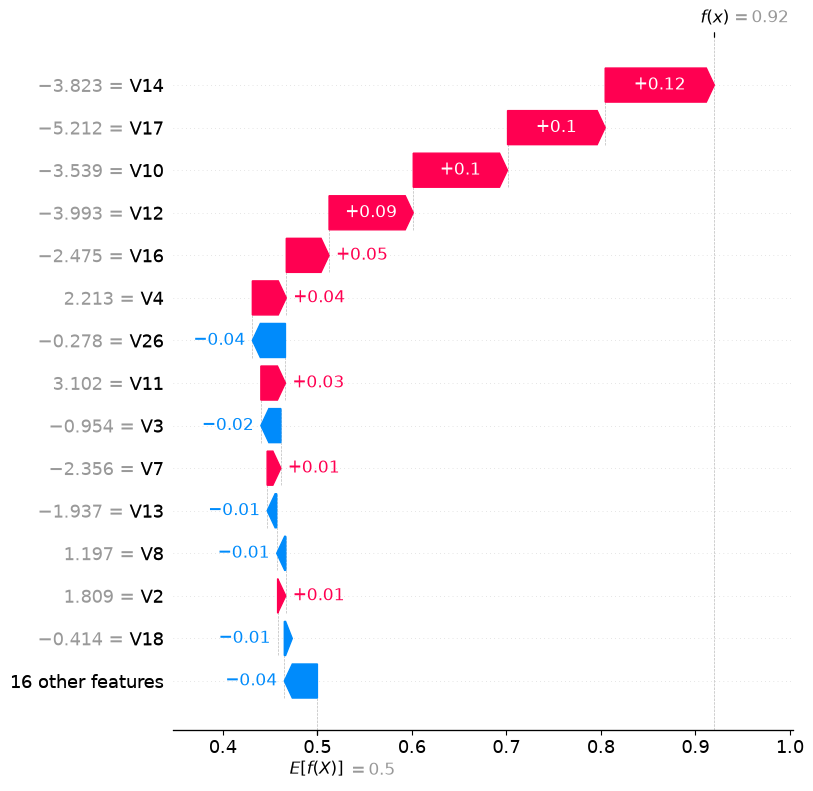

In [40]:
shap.waterfall_plot(
    shap.Explanation(
        values=shap_fraud_class[0],
        base_values=explainer.expected_value[1],
        data=X_fraud_one.iloc[0],
        feature_names=X_fraud_one.columns
    ),
    max_display=15
)

In [41]:
import joblib
import os

# Create models folder
os.makedirs("../models", exist_ok=True)

# Save trained Random Forest
joblib.dump(final_model, "../models/fraud_detection_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [1]:
import pandas as pd

# Load the saved test features and labels
X_test = pd.read_csv("../data/processed/X_test.csv")
y_test = pd.read_csv("../data/processed/y_test.csv").squeeze()

# Find a real fraud transaction
fraud_index = y_test[y_test == 1].index[0]

# Get that transaction's feature values
transaction = X_test.iloc[fraud_index]

print("Transaction index:", fraud_index)
print("Actual class:", y_test.iloc[fraud_index])
print(transaction.to_dict())

Transaction index: 845
Actual class: 1
{'Time': -0.4367666881825479, 'V1': -1.54878809850026, 'V2': 1.80869795041448, 'V3': -0.953509033832342, 'V4': 2.21308539346999, 'V5': -2.01572779170327, 'V6': -0.913456844516923, 'V7': -2.35601298316433, 'V8': 1.19716896702387, 'V9': -1.67837405659509, 'V10': -3.53865023182429, 'V11': 3.1020899271543, 'V12': -3.99337305447702, 'V13': -1.93741062327519, 'V14': -3.82289410599595, 'V15': 0.830970110708369, 'V16': -2.47535885382925, 'V17': -5.21187516766885, 'V18': -0.413871678166879, 'V19': 0.933262164554872, 'V20': 0.390785963777347, 'V21': 0.855138263312025, 'V22': 0.77474482148342, 'V23': 0.0590371520063436, 'V24': 0.343199807900813, 'V25': -0.468937928609185, 'V26': -0.278337986906642, 'V27': 0.625922215184372, 'V28': 0.395573378256676, 'Amount': -0.046577235374396}


In [2]:
import pandas as pd
import joblib
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Load raw dataset and repeat duplicate removal
df_raw = pd.read_csv("../data/raw/creditcard.csv")
df_raw = df_raw.drop_duplicates().reset_index(drop=True)

X_raw = df_raw.drop(columns=["Class"])
y_raw = df_raw["Class"]

# Recreate the original 80/20 stratified split
X_train_raw, X_test_raw, y_train_raw, y_test_raw = train_test_split(
    X_raw,
    y_raw,
    test_size=0.2,
    random_state=42,
    stratify=y_raw
)

# Fit scaler on unscaled training values only
scaler = StandardScaler()
scaler.fit(X_train_raw[["Time", "Amount"]])

# Save the corrected scaler
joblib.dump(scaler, "../models/scaler.pkl")

print("Correct scaler saved!")
print("Training Time mean:", scaler.mean_[0])
print("Training Amount mean:", scaler.mean_[1])

Correct scaler saved!
Training Time mean: 94900.22438981409
Training Amount mean: 88.38712432813462


In [3]:
# Convert the already-scaled test row back to original units
transaction_raw = X_test.iloc[[845]].copy()

transaction_raw[["Time", "Amount"]] = scaler.inverse_transform(
    transaction_raw[["Time", "Amount"]]
)

print(transaction_raw.iloc[0].to_dict())

{'Time': 74159.0, 'V1': -1.54878809850026, 'V2': 1.80869795041448, 'V3': -0.953509033832342, 'V4': 2.21308539346999, 'V5': -2.01572779170327, 'V6': -0.913456844516923, 'V7': -2.35601298316433, 'V8': 1.19716896702387, 'V9': -1.67837405659509, 'V10': -3.53865023182429, 'V11': 3.1020899271543, 'V12': -3.99337305447702, 'V13': -1.93741062327519, 'V14': -3.82289410599595, 'V15': 0.830970110708369, 'V16': -2.47535885382925, 'V17': -5.21187516766885, 'V18': -0.413871678166879, 'V19': 0.933262164554872, 'V20': 0.390785963777347, 'V21': 0.855138263312025, 'V22': 0.77474482148342, 'V23': 0.0590371520063436, 'V24': 0.343199807900813, 'V25': -0.468937928609185, 'V26': -0.278337986906642, 'V27': 0.625922215184372, 'V28': 0.395573378256676, 'Amount': 76.94000000000001}


In [4]:
# Find a legitimate transaction in the test dataset
legit_indices = y_test[y_test == 0].index

legit_index = legit_indices[0]

# Get its feature values
legit_transaction = X_test.loc[[legit_index]]

print("Transaction index:", legit_index)
print("Actual class:", y_test.loc[legit_index])
print(legit_transaction.iloc[0].to_dict())

Transaction index: 0
Actual class: 0
{'Time': -0.7077608399541054, 'V1': 1.2288211502379, 'V2': -0.0634077165201056, 'V3': 0.274145142235826, 'V4': 0.647465021810117, 'V5': -0.0481345611508765, 'V6': 0.372073028593297, 'V7': -0.22423058741343, 'V8': 0.0799390492455152, 'V9': 0.640758817066441, 'V10': -0.273053702248503, 'V11': -1.25272793883718, 'V12': 0.465078770741453, 'V13': 0.400502115321077, 'V14': -0.292841860600363, 'V15': -0.10177401599731, 'V16': -0.399835897844616, 'V17': 0.0343356567914817, 'V18': -0.783550254934187, 'V19': 0.141344900433949, 'V20': -0.0965659023514416, 'V21': -0.129554448055005, 'V22': -0.0837793282428063, 'V23': -0.151661473916324, 'V24': -0.700371597289218, 'V25': 0.598550164523483, 'V26': 0.491409070563651, 'V27': 0.0029892597250263, 'V28': 0.0017822861144491, 'Amount': -0.3128462297111745}


In [5]:
legit_transaction_raw = legit_transaction.copy()

legit_transaction_raw[["Time", "Amount"]] = scaler.inverse_transform(
    legit_transaction_raw[["Time", "Amount"]]
)

print(legit_transaction_raw.iloc[0].to_dict())

{'Time': 61290.0, 'V1': 1.2288211502379, 'V2': -0.0634077165201056, 'V3': 0.274145142235826, 'V4': 0.647465021810117, 'V5': -0.0481345611508765, 'V6': 0.372073028593297, 'V7': -0.22423058741343, 'V8': 0.0799390492455152, 'V9': 0.640758817066441, 'V10': -0.273053702248503, 'V11': -1.25272793883718, 'V12': 0.465078770741453, 'V13': 0.400502115321077, 'V14': -0.292841860600363, 'V15': -0.10177401599731, 'V16': -0.399835897844616, 'V17': 0.0343356567914817, 'V18': -0.783550254934187, 'V19': 0.141344900433949, 'V20': -0.0965659023514416, 'V21': -0.129554448055005, 'V22': -0.0837793282428063, 'V23': -0.151661473916324, 'V24': -0.700371597289218, 'V25': 0.598550164523483, 'V26': 0.491409070563651, 'V27': 0.0029892597250263, 'V28': 0.0017822861144491, 'Amount': 11.500000000000014}


In [1]:

import json
import joblib
import pandas as pd

from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Project root directory
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

# Load the saved model and held-out test data
model = joblib.load(ROOT / "models" / "fraud_detection_model.pkl")

X_test = pd.read_csv(ROOT / "data" / "processed" / "X_test.csv")
y_test_df = pd.read_csv(ROOT / "data" / "processed" / "y_test.csv")

# Handle either a one-column target CSV or a named Class column
y_test = y_test_df["Class"] if "Class" in y_test_df.columns else y_test_df.iloc[:, 0]

# Generate predictions and fraud probabilities
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
tn, fp, fn, tp = confusion_matrix(
    y_test, y_pred, labels=[0, 1]
).ravel()

metrics = {
    "model_name": "Random Forest",
    "evaluation_dataset": "Held-out test set",
    "test_samples": int(len(y_test)),
    "actual_fraud_cases": int((y_test == 1).sum()),
    "accuracy": float(accuracy_score(y_test, y_pred)),
    "precision": float(precision_score(y_test, y_pred, zero_division=0)),
    "recall": float(recall_score(y_test, y_pred, zero_division=0)),
    "f1_score": float(f1_score(y_test, y_pred, zero_division=0)),
    "pr_auc": float(average_precision_score(y_test, y_prob)),
    "roc_auc": float(roc_auc_score(y_test, y_prob)),
    "confusion_matrix": {
        "true_negatives": int(tn),
        "false_positives": int(fp),
        "false_negatives": int(fn),
        "true_positives": int(tp)
    }
}

# Save metrics for the Streamlit dashboard
metrics_path = ROOT / "models" / "model_metrics.json"

with open(metrics_path, "w", encoding="utf-8") as file:
    json.dump(metrics, file, indent=4)

print(json.dumps(metrics, indent=4))
print(f"\nMetrics saved to: {metrics_path}")


{
    "model_name": "Random Forest",
    "evaluation_dataset": "Held-out test set",
    "test_samples": 56746,
    "actual_fraud_cases": 95,
    "accuracy": 0.9994889507630493,
    "precision": 0.9583333333333334,
    "recall": 0.7263157894736842,
    "f1_score": 0.8263473053892215,
    "pr_auc": 0.8148634141015343,
    "roc_auc": 0.9426053704631034,
    "confusion_matrix": {
        "true_negatives": 56648,
        "false_positives": 3,
        "false_negatives": 26,
        "true_positives": 69
    }
}

Metrics saved to: c:\Users\ACER\credit-card-fraud-detection\models\model_metrics.json
